# 07c ARMA and ARIMA

07a went straight to ARIMA and SARIMA. Here we fill in the step below them, ARMA(p, q), so the whole ladder is on
the same backtest. ARMA has two halves. The AR(p) half says today depends on the last p days. The MA(q) half says
today depends on the last q surprises, the gaps between what was expected and what sold. We fit each half on its own
first, because it shows what each one brings, and then the two together. ARMA does not difference the data (d = 0),
so it assumes each product moves around a fixed mean. That is only true for some products, so we also score it on
the products that both stationarity tests in 05 call stationary. ARMA and ARIMA are building blocks: they are not
tuned and are not part of the headline.

## Load

In [1]:
import os, sys, warnings
sys.path.append("../src")
os.environ["PYTHONPATH"] = os.path.abspath("../src")    # the joblib workers need src/ too
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

from config import ROOT, PROCESSED, TABLES, FIGS, EVAL_ORIGINS, CATEGORIES, FIG_STYLE, COLORS
import ts_models as tm
from evaluation import METRICS, mase_scales

RERUN = False
N_JOBS = 10
FITS = PROCESSED / "ts_fits"
MAXO = 7
plt.rcParams.update(FIG_STYLE)
written = []

inp = tm.load_inputs()
series, sample, flags, prices = inp["series"], inp["sample"], inp["flags"], inp["prices"]
scales = mase_scales(inp["daily"], tm.ALL_ORIGINS)
warm = tm.VAL_ORIGINS[-1]
st = pd.read_csv(TABLES / "stationarity_items.csv").set_index("item_id")
stationary = [i for i in series if st.loc[i, "label"] == "stationary"]
print(f"{len(series)} products, {len(stationary)} of them stationary by both ADF and KPSS")
print(st.loc[list(series), "label"].value_counts().to_string())

150 products, 33 of them stationary by both ADF and KPSS
label
conflicting              91
stationary               33
difference-stationary    22
trend-stationary          4


## ACF and PACF of three products

On the last 730 days before the warm-up origin, one product per category. The autocorrelation (ACF) shows how
today's sales relate to sales k days ago; the partial autocorrelation (PACF) shows the same after the days in
between are accounted for. A PACF that stops after lag p points to AR(p), an ACF that stops after lag q to MA(q).

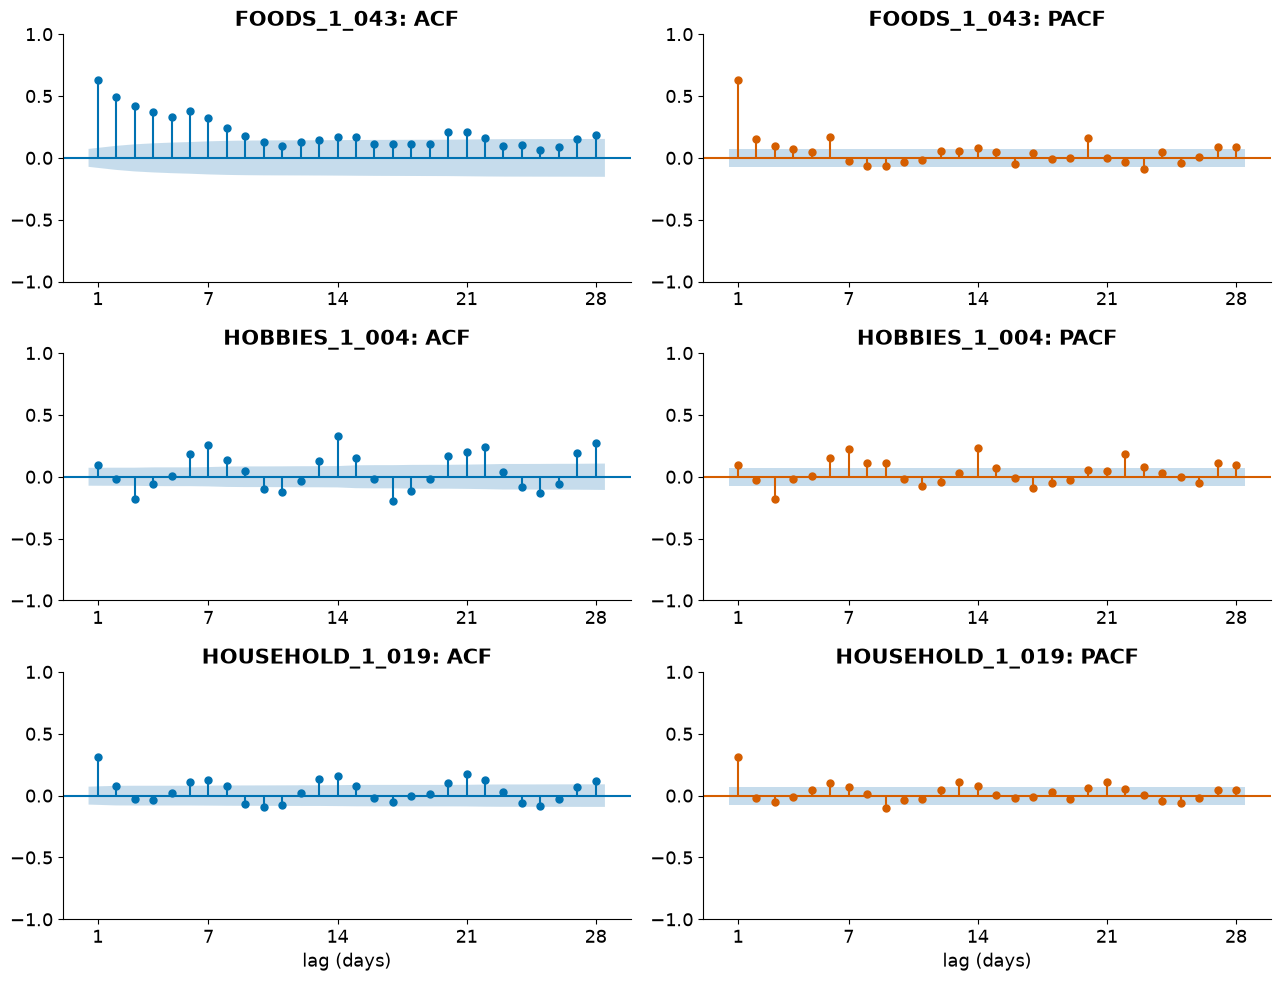

In [2]:
ex = sample.groupby("category")["item_id"].first().tolist()
fig, axes = plt.subplots(3, 2, figsize=(13, 10))
for row, i in zip(axes, ex):
    y, _ = tm.window(series[i]["sales"], series[i]["date"], warm)
    plot_acf(y, lags=28, ax=row[0], zero=False, color="#0072B2", vlines_kwargs={"colors": "#0072B2"})
    plot_pacf(y, lags=28, ax=row[1], zero=False, method="ywm", color="#D55E00", vlines_kwargs={"colors": "#D55E00"})
    row[0].set_title(f"{i}: ACF")
    row[1].set_title(f"{i}: PACF")
    for ax in row:
        ax.set_xticks([1, 7, 14, 21, 28])
for ax in axes[-1]:
    ax.set_xlabel("lag (days)")
fig.tight_layout()
fig.savefig(FIGS / "ts_acf_pacf_examples.png")
written.append(FIGS / "ts_acf_pacf_examples.png")
plt.show()

The three products look quite different. FOODS_1_043 has an ACF that dies away slowly, with bumps at 7, 14, 21 and 28,
and a PACF with one big spike at lag 1 and a smaller one at 6: a product whose level wanders, with a weekly rhythm
on top. HOBBIES_1_004 is almost all weekly rhythm: the ACF peaks at 7, 14, 21 and 28 and is close to zero in between,
and the PACF has spikes at 7 and 14. HOUSEHOLD_1_019 has a short memory (lag 1 in both plots) and a weak weekly echo.

What this told us about the orders: none of the PACFs stops cleanly after a few lags, and none of the ACFs either. The
weekly spikes are the reason. A pure AR or MA model can only reach the same weekday last week if its order is at
least 7, so the grid had to go up to 7, and a weekly-seasonal model should need far fewer terms. The AICc search
agreed: FOODS_1_043 took AR(6), MA(7) and ARMA(4, 4), HOBBIES_1_004 AR(7), MA(7) and ARMA(6, 7), and HOUSEHOLD_1_019
AR(7), MA(2) and ARMA(4, 4).

## Choosing the orders

For every product we fit all ARMA(p, q) with p and q from 0 to 7 on the warm-up window, with a constant and no
differencing, and record the AICc. The AR half alone is the best of the q = 0 column, the MA half alone the best of
the p = 0 row, and ARMA the best of the whole grid. That is 64 fits per product, about half an hour in total.

In [3]:
path = PROCESSED / "ts_arma_grid.parquet"
def grid_one(i):
    y, _ = tm.window(series[i]["sales"], series[i]["date"], warm)
    return tm.arma_grid(y, range(MAXO + 1), range(MAXO + 1)).assign(item_id=i)

if RERUN or not path.exists():
    grid = pd.concat(Parallel(n_jobs=N_JOBS, batch_size=1)(delayed(grid_one)(i) for i in series), ignore_index=True)
    grid.to_parquet(path, index=False)
grid = pd.read_parquet(path)
written.append(path)

def best(g):
    g = g.dropna(subset=["aicc"])
    return g.loc[g["aicc"].idxmin(), ["p", "q", "aicc"]] if len(g) else pd.Series({"p": 0, "q": 0, "aicc": np.nan})

ords = []
for i, g in grid.groupby("item_id"):
    a, m, b = best(g[g["q"] == 0]), best(g[g["p"] == 0]), best(g)
    ords.append({"item_id": i, "ar_p": int(a["p"]), "ma_q": int(m["q"]), "arma_p": int(b["p"]), "arma_q": int(b["q"]),
                 "ar_aicc": a["aicc"], "ma_aicc": m["aicc"], "arma_aicc": b["aicc"],
                 "grid_failed": int(g["aicc"].isna().sum())})
ords = pd.DataFrame(ords).set_index("item_id")
ords.to_csv(TABLES / "ts_arma_orders.csv")
written.append(TABLES / "ts_arma_orders.csv")
print("fits that failed in the grid:", int(ords["grid_failed"].sum()), "of", len(grid))
print("\nAR order p:", ords["ar_p"].value_counts().sort_index().to_dict())
print("MA order q:", ords["ma_q"].value_counts().sort_index().to_dict())
print("ARMA (p, q), most common:", (ords["arma_p"].astype(str) + "," + ords["arma_q"].astype(str)).value_counts().head(6).to_dict())

fits that failed in the grid: 0 of 9600

AR order p: {0: 8, 1: 1, 2: 1, 3: 6, 4: 2, 5: 5, 6: 12, 7: 115}
MA order q: {0: 9, 1: 5, 2: 3, 3: 6, 4: 4, 5: 3, 6: 5, 7: 115}
ARMA (p, q), most common: {'7,7': 30, '6,7': 14, '5,7': 11, '4,4': 9, '5,6': 9, '3,4': 7}


## The backtest

Each chosen order stays fixed, and the parameters are fitted again at every origin on the last 730 days, as in 07a.
We also refit ARIMA with the 07a orders at the two earlier validation origins, so every model here has the same nine
origins; at the scored origins it must equal 07a.

In [4]:
specs = {
    "ar": lambda i: {"kind": "sarima", "order": (int(ords.loc[i, "ar_p"]), 0, 0)},
    "ma": lambda i: {"kind": "sarima", "order": (0, 0, int(ords.loc[i, "ma_q"]))},
    "arma": lambda i: {"kind": "sarima", "order": (int(ords.loc[i, "arma_p"]), 0, int(ords.loc[i, "arma_q"]))},
    "arima": lambda i: {"kind": "sarima", "order": inp["orders"].loc[i, "arima_order"]},
}
fc = pd.concat([tm.run_model(f"block_{m}", s, series, tm.ALL_ORIGINS, FITS, flags, prices, N_JOBS, RERUN).assign(model=m)
                for m, s in specs.items()], ignore_index=True)
old = pd.read_parquet(TABLES / "classical_forecasts.parquet")
chk = fc[fc["model"] == "arima"].merge(old[old["model"] == "arima"], on=["item_id", "origin", "date"])
print("ARIMA refit against 07a, largest difference:", float((chk["forecast_x"] - chk["forecast_y"]).abs().max()))
sar = old[old["model"] == "sarima"][["item_id", "origin", "date", "model", "forecast"]]      # 07a, scored origins only
print(tm.fit_stats(fc).round(3).to_string())

ARIMA refit against 07a, largest difference: 0.0
       fits  fallback_rate  not_converged_rate
model                                         
ar     1350            0.0               0.000
arima  1350            0.0               0.052
arma   1350            0.0               0.936
ma     1350            0.0               0.000


## The ladder

Median across products of each product's mean over the six scored origins, on all 150 products and on the
stationary ones only. The AR and MA rows are ARMA's two halves on their own. SARIMA is the 07a model.

In [5]:
LADDER = ["ar", "ma", "arma", "arima", "sarima"]
NAME = {"ar": "AR(p)", "ma": "MA(q)", "arma": "ARMA(p, q)", "arima": "ARIMA", "sarima": "SARIMA"}
both = pd.concat([tm.for_scoring(fc)[sar.columns], sar], ignore_index=True)
pi = tm.per_item(tm.item_scores(both, inp["actuals"], scales), EVAL_ORIGINS)
rows = []
for grp, ids in [("all 150", list(series)), (f"stationary ({len(stationary)})", stationary)]:
    med = pi[pi["item_id"].isin(ids)].groupby("model")[METRICS].median()
    for m in LADDER:
        rows.append({"products": grp, "model": m, "name": NAME[m], **med.loc[m].to_dict()})
ladder = pd.DataFrame(rows)
ladder.to_csv(TABLES / "ts_ladder.csv", index=False)
written.append(TABLES / "ts_ladder.csv")
ladder.pivot(index="name", columns="products", values=["rmse", "mae", "mape"]).loc[[NAME[m] for m in LADDER]].round(3)

rmse                     mae                    mape  \
products   all 150 stationary (33) all 150 stationary (33) all 150   
name                                                                 
AR(p)        4.761           4.621   3.922           3.506   0.640   
MA(q)        5.288           5.301   4.299           4.275   0.641   
ARMA(p, q)   4.542           4.414   3.577           3.435   0.617   
ARIMA        4.822           4.600   3.775           3.393   0.638   
SARIMA       4.445           4.444   3.522           3.462   0.603   

                            
products   stationary (33)  
name                        
AR(p)                0.656  
MA(q)                0.622  
ARMA(p, q)           0.632  
ARIMA                0.622  
SARIMA               0.603

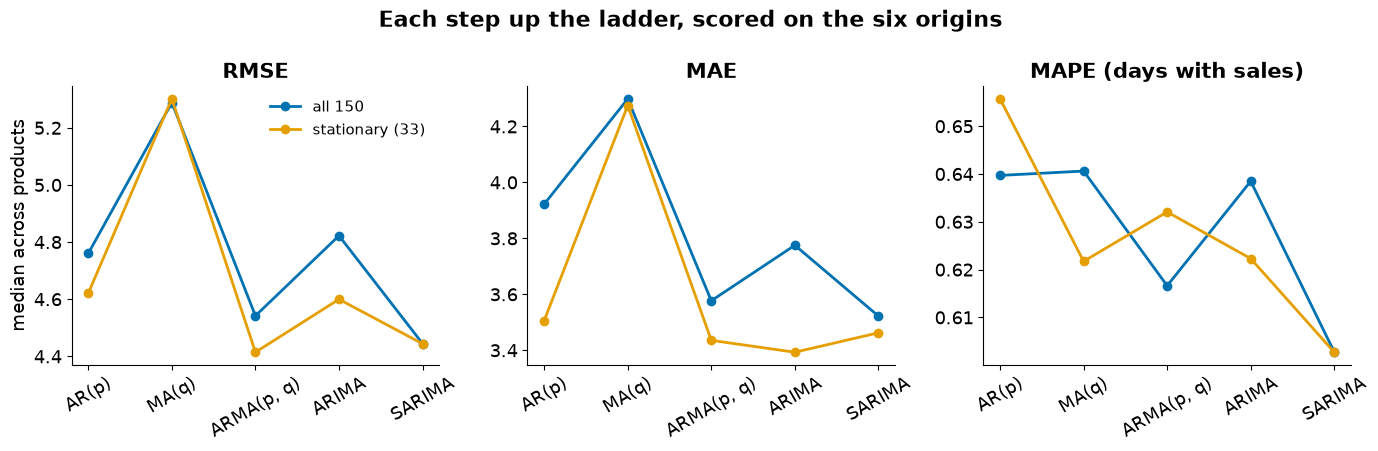

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, k, title in zip(axes, ["rmse", "mae", "mape"], ["RMSE", "MAE", "MAPE (days with sales)"]):
    for grp, color in zip(ladder["products"].unique(), ["#0072B2", "#E69F00"]):
        x = ladder[ladder["products"] == grp].set_index("model").loc[LADDER]
        ax.plot([NAME[m] for m in LADDER], x[k], "o-", color=color, lw=2, label=grp)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("median across products")
axes[0].legend(frameon=False)
fig.suptitle("Each step up the ladder, scored on the six origins", fontsize=16, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGS / "ts_ladder.png")
written.append(FIGS / "ts_ladder.png")
plt.show()

## Ljung-Box on the residuals

If a model has caught the pattern, what it leaves behind should look like noise. Ljung-Box tests that at lags 7 and
14 on each product's warm-up fit; a product passes if both p-values are above 0.05 (the same rule as 07b, where
SARIMA and ARIMA were checked).

In [7]:
def lb(i):
    y, _ = tm.window(series[i]["sales"], series[i]["date"], warm)
    out = []
    for m in ["ar", "ma", "arma"]:
        res, ok = tm.fit_sarimax(y, specs[m](i)["order"])
        p = acorr_ljungbox(res.resid[7:], lags=[7, 14])["lb_pvalue"].to_numpy()
        out.append({"item_id": i, "model": m, "lb_p7": p[0], "lb_p14": p[1], "passes": bool((p > 0.05).all())})
    return out

lbt = pd.DataFrame([r for rows_ in Parallel(n_jobs=N_JOBS)(delayed(lb)(i) for i in series) for r in rows_])
lbt.to_csv(TABLES / "ts_blocks_ljung_box.csv", index=False)
written.append(TABLES / "ts_blocks_ljung_box.csv")
prev = pd.read_csv(TABLES / "diagnostics_items.csv")
prev = prev[prev["series"].isin(series) & prev["model"].isin(["arima", "sarima"])].groupby("model")["lb_pass"].mean()
share = pd.concat([lbt.groupby("model")["passes"].mean(), prev]).rename("share passing Ljung-Box").loc[LADDER]
share.rename(index=NAME).round(3)

model
AR(p)         0.687
MA(q)         0.213
ARMA(p, q)    0.973
ARIMA         0.287
SARIMA        0.820
Name: share passing Ljung-Box, dtype: float64

## Save

In [8]:
out = fc.merge(inp["actuals"], on=["item_id", "date"]).merge(sample[["item_id", "category"]], on="item_id")
out.to_parquet(TABLES / "ts_blocks_forecasts.parquet", index=False)
written.append(TABLES / "ts_blocks_forecasts.parquet")
assert out.groupby(["model", "item_id", "origin"]).size().eq(28).all() and out["forecast"].notna().all()

## What we found

The orders went as high as the grid allowed. On its own, the AR half chose lag 7 for 115 of the 150 products, and so
did the MA half. The most common ARMA was (7, 7), for 30 products. That is the weekly pattern again: without a
seasonal term, a model needs a lag of 7 to see last week.

Each half alone is clearly weaker than the two together. Median RMSE on the six scored origins is 4.761 for the AR
half, 5.288 for the MA half and 4.542 for ARMA. The MA half is the weakest, because a few past surprises say little
about next month. The AR half carries most of the signal, and adding the MA half takes ARMA a good step further.

ARMA then beats ARIMA clearly (4.542 against 4.822) and is only 2% behind SARIMA (4.445). MAE gives the same order
(ARMA 3.577, ARIMA 3.775, SARIMA 3.522). ARIMA differences the data, has orders of at most 2 and has no weekly term,
so it loses the weekly pattern that ARMA keeps through its lag-7 terms. SARIMA gets that pattern with two seasonal
parameters instead of seven.

On the 33 products that both ADF and KPSS call stationary, the gap closes completely: ARMA has an RMSE of 4.414
against 4.444 for SARIMA, and the lowest MASE of the three (0.774 against 0.782). On MAE, ARIMA is best in this group
(3.393), with ARMA at 3.435 and SARIMA at 3.462. That fits the theory: when a product does move around a fixed mean,
a model without differencing loses nothing.

The residual checks favour the long model. ARMA leaves white-noise residuals (Ljung-Box at lags 7 and 14) for 97% of
products, SARIMA for 82% and ARIMA for 29%; the halves on their own manage 69% (AR) and 21% (MA). The long ARMA fits
are not always easy, though: 94% of them stopped before the optimiser converged, against 5% for ARIMA. ARMA and
ARIMA are building blocks. They show why the seasonal term matters, but neither goes into the headline.

## What comes next

`07d_sarima_family` tunes SARIMA and adds the regressors that make it SARIMAX.

In [9]:
# files this notebook wrote
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

outputs\figures\ts_acf_pacf_examples.png 118 KB
data\processed\ts_arma_grid.parquet 100 KB
outputs\tables\ts_arma_orders.csv 12 KB
outputs\tables\ts_ladder.csv 1 KB
outputs\figures\ts_ladder.png 172 KB
outputs\tables\ts_blocks_ljung_box.csv 29 KB
outputs\tables\ts_blocks_forecasts.parquet 1,281 KB
